# Gabarito dos exercícios

Soluções comentadas dos exercícios dos notebooks 01 a 06. Quase sempre há mais de uma solução certa: se a sua for diferente e chegar ao mesmo resultado, ótimo.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from pixfraud.anomaly import isolation_forest
from pixfraud.graph import adjacency_matrix, build_graph, describe, graph_from_csv, money_trail
from pixfraud.patterns import PATTERNS, fan_in, fan_out, fraud_nodes, inject, mule_ring
from pixfraud.simulation import SimulationConfig, generate_dataset, load_dataset
from pixfraud.visualization import draw_graph, save_graph

A = graph_from_csv("dados/exemplo_transacoes.csv")
M = graph_from_csv("dados/exemplo_transacoes.csv", aggregate=False, parse_dates=["timestamp"])
contas, tx = load_dataset("../data/synthetic")
G = build_graph(tx, contas["account_id"])
papel = contas.set_index("account_id")["role"]

## Notebook 01 · Fundamentos

### 1. Grau × força

In [2]:
entrada = pd.Series(dict(A.in_degree()))
forca = pd.Series(dict(A.in_degree(weight="amount")))
print("maior grau de entrada: ", entrada.idxmax(), entrada.max())
print("maior força de entrada:", forca.idxmax(), forca.max())

maior grau de entrada:  padaria 4
maior força de entrada: conta_x 3600.0


A `padaria` recebe de 4 contas diferentes, mas são pagamentos pequenos (R\$ 44,50 no total). Já a `conta_x` recebe de só 2 contas, num total de R\$ 3.600. O grau conta **com quantas contas** há relação, e a força soma **quanto dinheiro** passou. Uma laranja típica tem poucas contas e muito dinheiro.

### 2. Matriz ponderada

In [3]:
W = adjacency_matrix(A, weight="amount")
resumo = pd.DataFrame({
    "enviou (soma da linha)": W.sum(axis=1),
    "recebeu (soma da coluna)": W.sum(axis=0),
    "out_degree(weight)": pd.Series(dict(A.out_degree(weight="amount"))),
})
print("linhas = out_degree ponderado?", np.allclose(resumo.iloc[:, 0], resumo.iloc[:, 2]))
resumo

linhas = out_degree ponderado? True


,enviou (soma da linha),recebeu (soma da coluna),out_degree(weight)
ana,77.5,43.0,77.5
bruno,48.0,100.0,48.0
padaria,0.0,44.5,0.0
carla,2725.0,30.0,2725.0
davi,110.0,70.0,110.0
conta_x,3459.0,3600.0,3459.0
conta_y,3300.0,3450.0,3300.0
conta_z,0.0,3300.0,0.0
elisa,308.0,60.0,308.0
mercado,0.0,380.0,0.0


### 3. Caminhos temporais

A ideia: percorrer os Pix do **mais recente para o mais antigo**, guardando para cada conta o último instante em que ela ainda pode mandar dinheiro que chega ao destino. Um Pix $u \to v$ no instante $t$ serve se $v$ ainda consegue repassar depois de $t$. É o algoritmo de *latest departure* para grafos temporais.

In [4]:
def alcancam_no_tempo(M, destino):
    ultimo = {destino: pd.Timestamp.max}
    for u, v, t in sorted(M.edges(data="timestamp"), key=lambda e: e[2], reverse=True):
        if v in ultimo and t <= ultimo[v]:
            ultimo[u] = max(ultimo.get(u, pd.Timestamp.min), t)
    return {u for u in ultimo if u != destino}


print("pelo grafo estático:", sorted(nx.ancestors(A, "conta_x")))
print("respeitando o tempo:", sorted(alcancam_no_tempo(M, "conta_x")))

pelo grafo estático: ['ana', 'bruno', 'carla', 'davi', 'elisa', 'fabio']
respeitando o tempo: ['ana', 'bruno', 'carla', 'fabio']


`ana` e `bruno` continuam valendo: ana → bruno (02/03, 12h10) → carla (02/03, 19h40) → conta_x (06/03) respeita a ordem cronológica. `davi` e `elisa` só se ligam a esse caminho por Pix feitos **depois** dos que viriam na sequência. Por exemplo, davi → bruno aconteceu em 07/03, depois do último bruno → carla.

### 4. Removendo uma aresta

In [5]:
H = A.copy()
H.remove_edge("bruno", "carla")
print(nx.number_strongly_connected_components(A), "->", nx.number_strongly_connected_components(H), "CFCs")
print("CFCs com mais de um vértice:", [sorted(c) for c in nx.strongly_connected_components(H) if len(c) > 1])

7 -> 8 CFCs
CFCs com mais de um vértice: [['ana', 'bruno', 'davi', 'elisa']]


`bruno → carla` era a única aresta que levava dinheiro do grupo até `carla`. Sem ela, ninguém do grupo alcança carla, e ela vira uma CFC sozinha. O resto do grupo continua fortemente conexo pelo ciclo ana → bruno → davi → elisa → ana.

### 5. Densidade

Num dígrafo simples com $n = 11$ vértices cabem $n(n-1) = 110$ arestas. Com 18 arestas, a densidade é $18/110 \approx 0{,}164$, que é o valor de `nx.density`.

## Notebook 02 · Construindo grafos

### 1. Janela de um dia

In [6]:
dia1 = build_graph(tx[tx["timestamp"] < "2026-01-02"])
tamanhos = sorted((len(c) for c in nx.weakly_connected_components(dia1)), reverse=True)
print(len(tamanhos), "componentes fracamente conexas")
print("a maior tem", tamanhos[0], "contas; as seguintes:", tamanhos[1:8])

151 componentes fracamente conexas
a maior tem 967 contas; as seguintes: [9, 7, 7, 7, 7, 6, 5]


### 2. Da vítima ao coletor

Um cuidado: na rede inteira, a partir de uma laranja dá para chegar a **qualquer** coletor. A laranja faz Pix de camuflagem para contas comuns, e da grande componente se alcançam todas as vítimas de todas as quadrilhas. Para achar o coletor da *mesma* quadrilha, seguimos o dinheiro só entre contas de fraude.

In [7]:
vitima = contas.loc[contas["is_victim"], "account_id"].iloc[0]
laranja = next(v for v in G.successors(vitima) if papel[v] == "laranja")

fraude = G.subgraph(contas.loc[contas["is_fraud"], "account_id"])
coletor = next(v for v in nx.descendants(fraude, laranja) if papel[v] == "coletor")

caminho = nx.shortest_path(G, vitima, coletor)
print("vítima:", vitima, "| pagou a laranja:", laranja)
print(" -> ".join(f"{v} ({papel[v]})" for v in caminho))
print("saltos até o coletor:", len(caminho) - 1)

vítima: C000001 | pagou a laranja: C001987
C000001 (normal) -> C001987 (laranja) -> C000555 (coletor)
saltos até o coletor: 2


### 3. Par com mais Pix

In [8]:
multi = graph_from_csv("../data/synthetic/transactions.csv", aggregate=False)
pares = pd.Series([f"{u} ({papel[u]}) -> {v} ({papel[v]})" for u, v in multi.edges()])
pares.value_counts().head(10)

C000687 (intermediario) -> C000333 (coletor)          42
C000182 (intermediario) -> C002097 (intermediario)    42
C002097 (intermediario) -> C000687 (intermediario)    42
C000749 (intermediario) -> C000908 (intermediario)    38
C000437 (intermediario) -> C001137 (coletor)          38
C000908 (intermediario) -> C000437 (intermediario)    38
C000752 (intermediario) -> C000995 (intermediario)    35
C000995 (intermediario) -> C001219 (intermediario)    35
C001219 (intermediario) -> C000528 (coletor)          35
C001527 (intermediario) -> C001956 (coletor)          34
Name: count, dtype: int64

Os pares com mais Pix são **repasses dentro das quadrilhas**: cada golpe gera um repasse em cada salto da cadeia, então os elos entre intermediários acumulam dezenas de Pix. O mesmo número está no atributo `count` do grafo agregado, e ele é um bom candidato a atributo (ex.: o maior `count` entre as arestas de saída de cada conta).

### 4. Arestas de maior valor

In [9]:
fraudulenta = contas.set_index("account_id")["is_fraud"]
arestas = pd.DataFrame(
    [(u, v, d["amount"], d["count"]) for u, v, d in G.edges(data=True)],
    columns=["origem", "destino", "valor", "pix"],
)
top = arestas.nlargest(10, "valor").assign(
    papéis=lambda df: df["origem"].map(papel) + " -> " + df["destino"].map(papel)
)
print("envolvem conta fraudulenta:", (top["origem"].map(fraudulenta) | top["destino"].map(fraudulenta)).sum(), "de 10")
top

envolvem conta fraudulenta: 10 de 10


,origem,destino,valor,pix,papéis
20413,C000182,C002097,13008.06,42,intermediario -> intermediario
20434,C002097,C000687,12357.78,42,intermediario -> intermediario
31410,C000687,C000333,11700.27,42,intermediario -> coletor
31772,C000752,C000995,10597.66,35,intermediario -> intermediario
31775,C000995,C001219,9970.87,35,intermediario -> intermediario
6145,C000749,C000908,9955.22,38,intermediario -> intermediario
32275,C001219,C000528,9456.28,35,intermediario -> coletor
31764,C000908,C000437,9352.63,38,intermediario -> intermediario
30425,C001296,C001039,9241.10,34,intermediario -> intermediario
29157,C000437,C001137,8799.06,38,intermediario -> coletor


As arestas de maior valor são quase todas da lavagem: os repasses concentram o dinheiro de muitos golpes. Isso sugere atributos **por aresta**, como o valor máximo recebido ou enviado numa única relação, e não só somas por conta.

### 5. Trilha para frente de uma vítima

In [10]:
vitima = contas.loc[contas["is_victim"], "account_id"].iloc[1]
frente = money_trail(G, vitima, max_hops=2, direction="forward")
print("para frente da vítima, 2 saltos:", frente.number_of_nodes(), "contas")
for saltos in (2, 3, 4):
    tras = money_trail(G, coletor, max_hops=saltos, direction="backward")
    print(f"para trás do coletor {coletor}, {saltos} saltos:", tras.number_of_nodes(), "contas")
save_graph(frente, "../data/processed/trilha_vitima.html", title=f"Para onde foi o dinheiro de {vitima}")

para frente da vítima, 2 saltos: 201 contas
para trás do coletor C000555, 2 saltos: 37 contas
para trás do coletor C000555, 3 saltos: 267 contas
para trás do coletor C000555, 4 saltos: 1105 contas


WindowsPath('../data/processed/trilha_vitima.html')

A vítima é uma pessoa comum: paga amigos e comércios, que pagam outros amigos e comércios… Em poucos saltos o recorte cobre boa parte da rede (é o "mundo pequeno" do notebook 05). Já o coletor só recebe dinheiro do golpe. Com o mesmo alcance de 2 saltos, a trilha para trás dele é estreita e mostra exatamente a quadrilha: laranjas e vítimas.

Mas repare no que acontece com mais saltos: o terceiro salto já sai da quadrilha e entra nos contatos das vítimas, e a trilha explode. O alcance certo depende da quadrilha (com ou sem cadeia de intermediários), por isso a direção, o ponto de partida **e** o alcance do recorte importam tanto.

## Notebook 03 · Métricas de centralidade

### 1. Gravata-borboleta

In [11]:
gravata = nx.DiGraph([("a", "m"), ("b", "m"), ("m", "c"), ("m", "d")])
print(nx.betweenness_centrality(gravata, normalized=False))
print(nx.betweenness_centrality(gravata))

{'a': 0.0, 'm': 4.0, 'b': 0.0, 'c': 0.0, 'd': 0.0}
{'a': 0.0, 'm': 0.3333333333333333, 'b': 0.0, 'c': 0.0, 'd': 0.0}


Os caminhos entre pares distintos são $a \to c$, $a \to d$, $b \to c$ e $b \to d$. Todos são únicos e todos passam por $m$, então $C_B(m) = 4$ e os demais valem 0. Normalizando: $4 / (4 \cdot 3) = 1/3$.

### 2. PageRank e $\alpha$

In [12]:
def pagerank_manual(G, alpha=0.85, weight="amount", iteracoes=100):
    M = adjacency_matrix(G, weight=weight).to_numpy()
    n = len(M)
    soma = M.sum(axis=1, keepdims=True)
    sem_saida = soma[:, 0] == 0
    P = np.divide(M, soma, out=np.zeros_like(M), where=soma > 0)
    r = np.full(n, 1 / n)
    for _ in range(iteracoes):
        r = alpha * (r @ P + r[sem_saida].sum() / n) + (1 - alpha) / n
    return pd.Series(r, index=list(G.nodes))


pd.DataFrame({
    "α = 0,85": pagerank_manual(A),
    "α = 0,5 (manual)": pagerank_manual(A, alpha=0.5),
    "α = 0,5 (networkx)": pd.Series(nx.pagerank(A, alpha=0.5, weight="amount")),
}).sort_values("α = 0,85", ascending=False).round(4)

,"α = 0,85","α = 0,5 (manual)","α = 0,5 (networkx)"
conta_z,0.1703,0.1197,0.1197
conta_y,0.1551,0.1223,0.1223
conta_x,0.1376,0.1277,0.1277
mercado,0.0868,0.0924,0.0924
bruno,0.0864,0.0965,0.0965
carla,0.0844,0.0887,0.0887
elisa,0.0687,0.0794,0.0794
davi,0.0652,0.0764,0.0764
padaria,0.0644,0.0770,0.0770
ana,0.0426,0.0613,0.0613


Com $\alpha$ menor, a moeda "salta" para uma conta aleatória com mais frequência e segue menos os Pix. Ela passa a percorrer cadeias longas com menos probabilidade, então as contas no fim do fluxo (`conta_z`, `conta_y`) perdem PageRank e a distribuição fica mais uniforme. No limite $\alpha = 0$, todas as contas teriam $1/n$.

### 3. Convergência

In [13]:
def pagerank_ate_convergir(G, alpha=0.85, weight="amount", tol=1e-8):
    M = adjacency_matrix(G, weight=weight).to_numpy()
    n = len(M)
    soma = M.sum(axis=1, keepdims=True)
    sem_saida = soma[:, 0] == 0
    P = np.divide(M, soma, out=np.zeros_like(M), where=soma > 0)
    r = np.full(n, 1 / n)
    for iteracao in range(1, 10_000):
        novo = alpha * (r @ P + r[sem_saida].sum() / n) + (1 - alpha) / n
        if np.abs(novo - r).sum() < tol:
            return pd.Series(novo, index=list(G.nodes)), iteracao
        r = novo


for alpha in (0.5, 0.85, 0.99):
    _, iteracoes = pagerank_ate_convergir(A, alpha=alpha)
    print(f"α = {alpha}: {iteracoes} iterações")

α = 0.5: 17 iterações
α = 0.85: 31 iterações
α = 0.99: 41 iterações


Quanto maior $\alpha$, mais iterações: o erro diminui aproximadamente por um fator $\alpha$ a cada passo, então a convergência é mais lenta quando $\alpha$ se aproxima de 1.

### 4. Reciprocidade por papel

In [14]:
ativas = [v for v in G if G.degree(v) > 0]
reciprocidade = pd.Series(nx.reciprocity(G, ativas))
reciprocidade.groupby(papel).median().round(3)

role
coletor          0.000
comercio         0.000
intermediario    0.000
laranja          0.000
normal           0.188
dtype: float64

As contas de fraude praticamente não devolvem dinheiro: a reciprocidade delas é zero. As pessoas comuns trocam Pix nos dois sentidos com amigos. Os comércios também têm reciprocidade zero (só recebem), então essa métrica ajuda a separar laranjas de pessoas, mas não de comércios.

### 5. Uma métrica para acrescentar

Resposta aberta. Uma boa candidata é a **reciprocidade** do exercício anterior: separa bem as contas de fraude das pessoas comuns, é barata de calcular e tem interpretação clara. Para acrescentá-la, basta uma linha em `graph_features` (`src/pixfraud/features.py`) e o nome em `GRAPH_FEATURES`. Depois é só rodar `scripts/rodar_experimento.py` e comparar as métricas com a versão anterior.

## Notebook 04 · Padrões de fraude

### 1. Gather-scatter

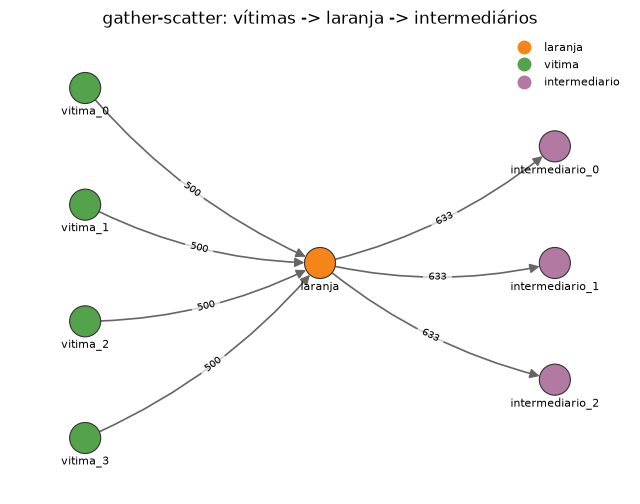

In [15]:
gather_scatter = nx.compose(fan_in(4, amount=500), fan_out(3, amount=1900))
draw_graph(gather_scatter, title="gather-scatter: vítimas -> laranja -> intermediários");

### 2. Sem camuflagem

In [16]:
contas4, tx4 = generate_dataset(SimulationConfig(n_people=800, n_merchants=40, n_rings=0, seed=7))
fundo = build_graph(tx4, contas4["account_id"])

com, sem = fundo, fundo
for i, (nome, criar) in enumerate(PATTERNS.items()):
    com = inject(com, criar(), prefix=nome, seed=i)
    sem = inject(sem, criar(), prefix=nome, camouflage=0, seed=i)

print("componentes fracas com camuflagem:", describe(com)["componentes fracamente conexas"])
print("componentes fracas sem camuflagem:", describe(sem)["componentes fracamente conexas"])
[sorted(c) for c in nx.weakly_connected_components(sem) if len(c) < 50]

componentes fracas com camuflagem: 1
componentes fracas sem camuflagem: 5


[['fan_out_intermediario_0',
  'fan_out_intermediario_1',
  'fan_out_intermediario_2',
  'fan_out_intermediario_3',
  'fan_out_intermediario_4',
  'fan_out_laranja'],
 ['chain_coletor',
  'chain_intermediario_1',
  'chain_intermediario_2',
  'chain_laranja'],
 ['cycle_intermediario_0',
  'cycle_intermediario_1',
  'cycle_intermediario_2',
  'cycle_intermediario_3'],
 ['scatter_gather_coletor',
  'scatter_gather_intermediario_0',
  'scatter_gather_intermediario_1',
  'scatter_gather_intermediario_2',
  'scatter_gather_intermediario_3',
  'scatter_gather_laranja']]

Sem camuflagem, os quatro padrões que não têm vítimas (`fan_out`, `chain`, `cycle` e `scatter_gather`) ficam **desconectados** do resto da rede. Encontrá-los seria trivial: bastaria listar as componentes pequenas. Em redes reais, contas de fraude também movimentam dinheiro "normal". A camuflagem obriga o detector a achar o padrão dentro da rede, como ele teria de fazer na prática.

### 3. Tamanho da cadeia

In [17]:
for tamanho in (1, 3, 6):
    H = inject(fundo, mule_ring(chain_length=tamanho), prefix="q", seed=0)
    percentil = pd.Series(nx.betweenness_centrality(H)).rank(pct=True)
    meio = [f"q_intermediario_{i}" for i in range(tamanho)]
    print(f"{tamanho} intermediário(s):", percentil[meio].round(3).tolist())

1 intermediário(s): [0.291]


3 intermediário(s): [0.738, 0.498, 0.233]


6 intermediário(s): [0.954, 0.905, 0.84, 0.71, 0.529, 0.2]


Um intermediário está no caminho mínimo de toda conta que alcança as vítimas (quase a rede inteira) até cada conta **depois** dele na cadeia. O primeiro intermediário tem todos os seguintes e o coletor "atrás de si", e o último só tem o coletor. Por isso a intermediação cai ao longo da cadeia, e cadeias maiores dão intermediação mais alta aos primeiros elos.

### 4. Um golpe sutil

In [18]:
def metricas_de(G):
    return pd.DataFrame({
        "grau de entrada": pd.Series(dict(G.in_degree())),
        "grau de saída": pd.Series(dict(G.out_degree())),
        "valor recebido": pd.Series(dict(G.in_degree(weight="amount"))),
        "intermediação": pd.Series(nx.betweenness_centrality(G, k=300, seed=0)),
        "PageRank": pd.Series(nx.pagerank(G, weight="amount")),
        "agrupamento": pd.Series(nx.clustering(G.to_undirected())),
    })


for nome, padrao in {"fan_in padrão (5 × R$ 500)": fan_in(), "fan_in sutil (2 × R$ 50)": fan_in(2, amount=50)}.items():
    H = inject(fundo, padrao, prefix="x", seed=0)
    escores = isolation_forest(metricas_de(H)).scores
    posicao = int(escores.rank(ascending=False)["x_laranja"])
    print(f"{nome}: a laranja é a {posicao}ª conta mais suspeita de {H.number_of_nodes()}")

fan_in padrão (5 × R$ 500): a laranja é a 33ª conta mais suspeita de 841


fan_in sutil (2 × R$ 50): a laranja é a 7ª conta mais suspeita de 841


**Surpresa:** a laranja sutil aparece *mais* suspeita que a padrão! Para entender, olhe para a rede de fundo:

In [19]:
graus = pd.Series(dict(fundo.degree()))
print("grau (entrada + saída) das contas legítimas:")
print(graus.describe().round(1).to_string())
print(f"\ncontas legítimas com grau ≤ 4: {(graus <= 4).mean():.1%}")
print("grau da laranja sutil:", inject(fundo, fan_in(2, amount=50), prefix="x", seed=0).degree("x_laranja"))

grau (entrada + saída) das contas legítimas:
count    840.0
mean      29.4
std       34.9
min        8.0
25%       20.0
50%       24.0
75%       31.0
max      671.0

contas legítimas com grau ≤ 4: 0.0%
grau da laranja sutil: 4


No gerador, **toda** pessoa legítima é bem ativa (cerca de 18 Pix enviados por mês, mais os recebidos). Uma conta com só 4 relações é raríssima nessa rede, então o Isolation Forest a destaca. Ele não está detectando o golpe: está detectando uma **conta quieta**. Numa rede real, cheia de contas pouco usadas, esse critério geraria muitos falsos positivos.

Duas lições para a pesquisa:

1. O resultado de um detector depende da **rede de fundo**. Um experimento só é justo se o fundo tiver a variedade da rede real. Aqui, o gerador precisaria de contas legítimas pouco ativas, o que é uma melhoria a anotar em `simulation.py` (ver as limitações em `data/README.md`).
2. Golpes pequenos, numa rede realista, tendem a se esconder no "ruído". Outros sinais ajudam nesses casos (idade da conta, horário, velocidade de repasse), e por isso a pesquisa compara e combina atributos tabulares e de grafo.

## Notebook 05 · Modelos de redes

### 1. Barabási–Albert

m = 1: grau máximo = 77
m = 2: grau máximo = 87
m = 5: grau máximo = 105


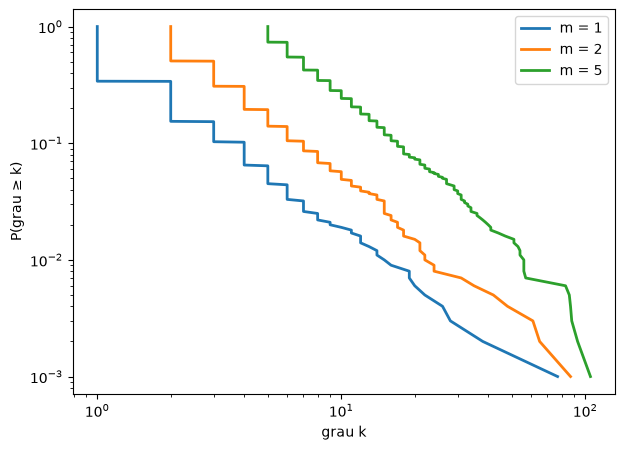

In [20]:
fig, ax = plt.subplots(figsize=(7, 5))
for m in (1, 2, 5):
    H = nx.barabasi_albert_graph(1000, m, seed=1)
    graus = np.sort([d for _, d in H.degree()])
    print(f"m = {m}: grau máximo = {graus.max()}")
    ax.loglog(graus, 1 - np.arange(len(graus)) / len(graus), label=f"m = {m}", lw=2)
ax.set_xlabel("grau k")
ax.set_ylabel("P(grau ≥ k)")
ax.legend();

As três curvas têm caudas aproximadamente **retas e paralelas** em escala log-log: é a lei de potência. No modelo BA, $P(\text{grau} = k) \propto k^{-3}$, então a acumulada cai como $k^{-2}$. Aumentar $m$ desloca a curva para a direita (mais arestas por vértice) sem mudar a inclinação. O grau máximo cresce com $m$.

### 2. Mundo pequeno

In [21]:
linhas = []
for p in (0, 0.01, 0.1, 1):
    H = nx.connected_watts_strogatz_graph(1000, 10, p, seed=1)
    linhas.append({
        "p": p,
        "agrupamento médio": nx.average_clustering(H),
        "distância média": nx.average_shortest_path_length(H),
    })
pd.DataFrame(linhas).round(3)

,p,agrupamento médio,distância média
0,0.00,0.667,50.450
1,0.01,0.651,9.623
2,0.10,0.493,4.426
3,1.00,0.010,3.271


Com $p = 0$ (anel regular), o agrupamento é alto e as distâncias são longas. Com $p = 1$ (quase aleatório), as distâncias são curtas e o agrupamento some. Entre $p = 0{,}01$ e $p = 0{,}1$, poucas arestas religadas já funcionam como "atalhos": a distância cai muito enquanto o agrupamento continua alto. Esse é o regime de **mundo pequeno**.

### 3. Hubs

In [22]:
def distancia_media(G, amostra=200, seed=0):
    maior = G.subgraph(max(nx.connected_components(G), key=len))
    rng = np.random.default_rng(seed)
    nos = list(maior)
    origens = [nos[i] for i in rng.choice(len(nos), size=min(amostra, len(nos)), replace=False)]
    soma = pares = 0
    for s in origens:
        distancias = nx.single_source_shortest_path_length(maior, s)
        soma += sum(distancias.values())
        pares += len(distancias) - 1
    return soma / pares


pix = nx.Graph(build_graph(tx).to_undirected())
hubs = sorted(pix.degree(), key=lambda x: x[1], reverse=True)[:10]
print(pd.DataFrame(hubs, columns=["conta", "grau"]).assign(papel=lambda df: df["conta"].map(papel)).to_string(index=False))

sem_hubs = pix.copy()
sem_hubs.remove_nodes_from([v for v, _ in hubs])
print(f"\ndistância média: com hubs = {distancia_media(pix):.3f} | sem os 10 hubs = {distancia_media(sem_hubs):.3f}")

  conta  grau    papel
C001118  1573 comercio
C000560  1095 comercio
C001505   819 comercio
C000499   669 comercio
C000323   494 comercio
C000093   436 comercio
C000862   377 comercio
C002051   353 comercio
C001916   282 comercio
C001022   279 comercio



distância média: com hubs = 2.233 | sem os 10 hubs = 2.792


Os hubs são os comércios mais populares. Sem eles, a distância média aumenta: os comércios funcionam como "atalhos" que ligam comunidades que não se conhecem. Na análise de fraudes, isso lembra que métricas de caminho (intermediação, distâncias) são dominadas pelos hubs legítimos. Às vezes vale calculá-las numa rede **sem os comércios** para enxergar melhor o resto.

## Notebook 06 · Tipo de rede

### 1. Ligação preferencial desligada

BA: grau máximo = 163, alpha = 2.71, KS = 0.009
sem preferência: grau máximo = 33, alpha = 6.83, KS = 0.027


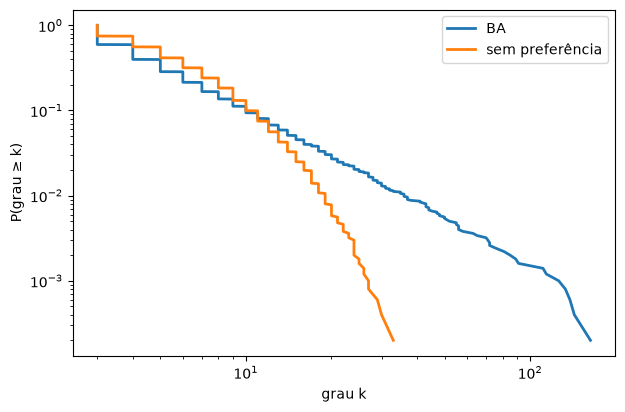

In [2]:
from pixfraud.algorithms import cosine_similarity, vector_angle
from pixfraud.network import degree_sequence, fit_power_law, giant_component


def ba_sem_preferencia(n, m, seed=0):
    rng = np.random.default_rng(seed)
    H = nx.complete_graph(m + 1)
    for novo in range(m + 1, n):
        alvos = rng.choice(novo, size=m, replace=False)  # uniforme entre os antigos
        H.add_edges_from((novo, int(a)) for a in alvos)
    return H


fig, ax = plt.subplots(figsize=(7, 4.5))
for nome, H in (("BA", nx.barabasi_albert_graph(5000, 3, seed=1)), ("sem preferência", ba_sem_preferencia(5000, 3))):
    k = np.sort(degree_sequence(H))
    ajuste = fit_power_law(k)
    print(f"{nome}: grau máximo = {k.max()}, alpha = {ajuste['alpha']:.2f}, KS = {ajuste['ks']:.3f}")
    ax.loglog(k, 1 - np.arange(len(k)) / len(k), lw=2, label=nome)
ax.set_xlabel("grau k"); ax.set_ylabel("P(grau ≥ k)"); ax.legend();

Sem a ligação preferencial, os vértices antigos ainda têm grau um pouco maior (tiveram mais tempo para receber ligações), mas a cauda cai **exponencialmente**: o grau máximo é bem menor e o $\alpha$ "ajustado" fica grande, sinal de que não é uma lei de potência. É preciso crescimento **e** preferência para chegar a $k^{-3}$.

### 2. Transição de fase

In [3]:
linhas = []
for n in (500, 1000, 4000):
    for k in (0.5, 1.5):
        fracoes = [len(giant_component(nx.gnp_random_graph(n, k / (n - 1), seed=s))) / n for s in range(5)]
        linhas.append({"n": n, "grau médio": k, "fração na gigante": np.mean(fracoes)})
pd.DataFrame(linhas).pivot(index="n", columns="grau médio", values="fração na gigante").round(3)

grau médio,0.5,1.5
n,,
500,0.016,0.590
1000,0.009,0.570
4000,0.004,0.592


Com $\langle k \rangle = 0{,}5$ a maior componente tem só algumas dezenas de vértices, então a **fração** cai para zero quando $n$ cresce: não existe componente gigante. Com $\langle k \rangle = 1{,}5$ a fração fica parada perto de $S \approx 0{,}58$, a solução de $S = 1 - e^{-1{,}5 S}$, qualquer que seja $n$. É isso que "gigante" quer dizer: uma fração constante da rede.

### 3. Cosseno à mão

$a \cdot b = 1\cdot 0 + 1 \cdot 1 + 0 \cdot 1 = 1$ e $\lVert a \rVert = \lVert b \rVert = \sqrt 2$, então $\cos\theta = 1/2$ e $\theta = 60°$.

In [4]:
a, b = [1, 1, 0], [0, 1, 1]
print(cosine_similarity(a, b), vector_angle(a, b))

0.4999999999999999 60.00000000000001


### 4. Coletora que esvazia

In [5]:
from dataclasses import replace

from pixfraud.network import random_walk_visits
from pixfraud.simulation import load_config

cfg = load_config("../configs/experimento.yaml")
for saidas in (0, 20):
    c, t = generate_dataset(replace(cfg, collector_cashout=saidas))
    H = build_graph(t, c["account_id"])
    coletoras = c.loc[c["role"] == "coletor", "account_id"]
    vitimas = c.loc[c["is_victim"], "account_id"]
    visitas = random_walk_visits(H, vitimas, walks_per_start=20, seed=0)
    print(f"collector_cashout = {saidas:2d}: grau de saída médio das coletoras = "
          f"{np.mean([H.out_degree(x) for x in coletoras]):.1f}; passeios que passam por alguma coletora = "
          f"{visitas.reindex(coletoras)['visitas'].sum():.2f}")

collector_cashout =  0: grau de saída médio das coletoras = 3.3; passeios que passam por alguma coletora = 0.20


collector_cashout = 20: grau de saída médio das coletoras = 22.7; passeios que passam por alguma coletora = 0.20


O grau de saída das coletoras sobe bastante: além dos ~3 Pix de camuflagem, elas passam a pagar ~20 contas. A fração de passeios que passam por elas quase não muda, porque o passeio chega na coletora do mesmo jeito; o que muda é que, com a coletora esvaziando o dinheiro, ele **continua** dali para pessoas e comércios. A coletora deixa de ser um "fim de linha" e vira uma conta de passagem com muito dinheiro: um padrão diferente para os detectores.